# Shopify Sales Data Analysis & Demand Prediction

## Business Objective

The objective of this project is to design data model for collecting,organizing and analysing shopify sales data and to develop a demand prediction approach to identify colors and design that are likely to experience higher demand during peak and seasonal peroids.

**The analysis will support:**
*product planning
*inventory management
*seasonal stock planning
*identification of high demand colors and design
*demand forecasting


In [37]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error
print("Libraries imported successfully")


Libraries imported successfully


In [38]:
#synthetic data
import random

np.random.seed(42)
random.seed(42)

# Create date range
dates = pd.date_range(
    start="2023-01-01",
    end="2025-12-31",
    freq="D"
)

# Product attributes
colors = [
    "Black",
    "White",
    "Red",
    "Blue",
    "Green",
    "Pink",
    "Yellow",
    "Beige"
]

designs = [
    "Floral",
    "Geometric",
    "Minimal",
    "Abstract",
    "Traditional",
    "Printed"
]

categories = [
    "T-Shirt",
    "Dress",
    "Shirt",
    "Top"
]

records = []

# Generate 6,000 sales records
for i in range(6000):

    order_date = random.choice(dates)

    color = random.choice(colors)
    design = random.choice(designs)
    category = random.choice(categories)

    product_id = f"P{random.randint(100, 199)}"
    customer_id = f"C{random.randint(1000, 1999)}"

    # Base demand
    quantity = np.random.poisson(3) + 1

    month = order_date.month

    # Summer demand
    if month in [3, 4, 5]:

        if color in ["White", "Yellow", "Pink"]:
            quantity += np.random.randint(1, 4)

        if design in ["Floral", "Printed"]:
            quantity += np.random.randint(1, 3)

    # Monsoon demand
    elif month in [6, 7, 8]:

        if color in ["Blue", "Green"]:
            quantity += np.random.randint(1, 3)

    # Festive / Winter demand
    elif month in [10, 11, 12]:

        if color in ["Red", "Black", "Green"]:
            quantity += np.random.randint(1, 4)

        if design in ["Traditional", "Printed"]:
            quantity += np.random.randint(1, 3)

    # Price
    unit_price = random.choice([
        499,
        599,
        699,
        799,
        999,
        1199
    ])

    # Discount
    discount = random.choice([
        0,
        5,
        10,
        15,
        20
    ])

    # Revenue
    revenue = quantity * unit_price * (1 - discount / 100)

    records.append([
        f"ORD{i+1:05d}",
        order_date,
        product_id,
        category,
        color,
        design,
        customer_id,
        quantity,
        unit_price,
        discount,
        round(revenue, 2)
    ])

sales_df = pd.DataFrame(
    records,
    columns=[
        "Order_ID",
        "Order_Date",
        "Product_ID",
        "Category",
        "Color",
        "Design",
        "Customer_ID",
        "Quantity",
        "Unit_Price",
        "Discount",
        "Revenue"
    ]
)

print("Synthetic dataset created successfully!")
print("Number of rows:", len(sales_df))


Synthetic dataset created successfully!
Number of rows: 6000


In [39]:
sales_df.head(10)

,Order_ID,Order_Date,Product_ID,Category,Color,Design,Customer_ID,Quantity,Unit_Price,Discount,Revenue
0,ORD00001,2023-08-17,P131,Shirt,Black,Printed,C1228,5,599,0,2995.00
1,ORD00002,2023-06-28,P111,T-Shirt,Yellow,Floral,C1223,2,599,20,958.40
2,ORD00003,2023-02-24,P128,Top,Blue,Printed,C1459,4,999,10,3596.40
3,ORD00004,2023-01-14,P143,Top,Red,Printed,C1284,4,599,5,2276.20
4,ORD00005,2024-11-20,P112,Top,White,Floral,C1367,3,699,20,1677.60
5,ORD00006,2024-06-25,P168,Top,Black,Printed,C1127,4,799,0,3196.00
6,ORD00007,2024-08-23,P190,Dress,Pink,Traditional,C1071,3,499,5,1422.15
7,ORD00008,2024-08-15,P148,T-Shirt,White,Geometric,C1284,4,799,10,2876.40
8,ORD00009,2023-11-30,P185,Dress,Pink,Minimal,C1273,1,1199,0,1199.00
9,ORD00010,2023-12-17,P148,Top,Blue,Geometric,C1276,3,1199,20,2877.60


In [40]:
print("Dataset Shape:")
print(sales_df.shape)

print("\nColumn Names:")
print(sales_df.columns.tolist())

print("\nData Types:")
print(sales_df.dtypes)

Dataset Shape:
(6000, 11)

Column Names:
['Order_ID', 'Order_Date', 'Product_ID', 'Category', 'Color', 'Design', 'Customer_ID', 'Quantity', 'Unit_Price', 'Discount', 'Revenue']

Data Types:
Order_ID                  str
Order_Date     datetime64[us]
Product_ID                str
Category                  str
Color                     str
Design                    str
Customer_ID               str
Quantity                int64
Unit_Price              int64
Discount                int64
Revenue               float64
dtype: object


In [41]:
#missing values checking
missing_values = sales_df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Order_ID       0
Order_Date     0
Product_ID     0
Category       0
Color          0
Design         0
Customer_ID    0
Quantity       0
Unit_Price     0
Discount       0
Revenue        0
dtype: int64


In [42]:
#check for duplicates
duplicate_count = sales_df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [43]:
sales_df.describe()

,Order_Date,Quantity,Unit_Price,Discount,Revenue
count,6000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2024-06-25 23:30:28.800000,4.706500,805.183333,10.045000,3408.545633
min,2023-01-01 00:00:00,1.000000,499.000000,0.000000,399.200000
25%,2023-09-26 00:00:00,3.000000,599.000000,5.000000,1998.000000
50%,2024-06-25 12:00:00,5.000000,799.000000,10.000000,3036.200000
75%,2025-03-25 00:00:00,6.000000,999.000000,15.000000,4473.800000
max,2025-12-31 00:00:00,14.000000,1199.000000,20.000000,15587.000000
std,NaN,2.076634,238.955260,7.090347,1881.331235


In [44]:
#time features adding
sales_df["Order_Date"] = pd.to_datetime(sales_df["Order_Date"])

sales_df["Year"] = sales_df["Order_Date"].dt.year
sales_df["Month"] = sales_df["Order_Date"].dt.month
sales_df["Month_Name"] = sales_df["Order_Date"].dt.month_name()
sales_df["Quarter"] = sales_df["Order_Date"].dt.quarter
sales_df["Day"] = sales_df["Order_Date"].dt.day
sales_df["Day_of_Week"] = sales_df["Order_Date"].dt.day_name()

print("Time features added successfully!")

sales_df.head()


Time features added successfully!


,Order_ID,Order_Date,Product_ID,Category,Color,Design,Customer_ID,Quantity,Unit_Price,Discount,Revenue,Year,Month,Month_Name,Quarter,Day,Day_of_Week
0,ORD00001,2023-08-17,P131,Shirt,Black,Printed,C1228,5,599,0,2995.0,2023,8,August,3,17,Thursday
1,ORD00002,2023-06-28,P111,T-Shirt,Yellow,Floral,C1223,2,599,20,958.4,2023,6,June,2,28,Wednesday
2,ORD00003,2023-02-24,P128,Top,Blue,Printed,C1459,4,999,10,3596.4,2023,2,February,1,24,Friday
3,ORD00004,2023-01-14,P143,Top,Red,Printed,C1284,4,599,5,2276.2,2023,1,January,1,14,Saturday
4,ORD00005,2024-11-20,P112,Top,White,Floral,C1367,3,699,20,1677.6,2024,11,November,4,20,Wednesday


In [45]:
#seasons
def assign_season(month):

    if month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8]:
        return "Monsoon"

    elif month in [9, 10, 11]:
        return "Festive"

    else:
        return "Winter"


sales_df["Season"] = sales_df["Month"].apply(assign_season)

sales_df["Is_Peak_Period"] = sales_df["Month"].isin(
    [3, 4, 5, 9, 10, 11, 12]
)

sales_df[[
    "Order_Date",
    "Month_Name",
    "Season",
    "Is_Peak_Period"
]].head(10)

,Order_Date,Month_Name,Season,Is_Peak_Period
0,2023-08-17,August,Monsoon,False
1,2023-06-28,June,Monsoon,False
2,2023-02-24,February,Winter,False
3,2023-01-14,January,Winter,False
4,2024-11-20,November,Festive,True
5,2024-06-25,June,Monsoon,False
6,2024-08-23,August,Monsoon,False
7,2024-08-15,August,Monsoon,False
8,2023-11-30,November,Festive,True
9,2023-12-17,December,Winter,True


In [46]:
sales_df.to_csv(
    "data/shopify_sales_data.csv",
    index=False
)

print("Dataset saved successfully!")
print("Location: data/shopify_sales_data.csv")

Dataset saved successfully!
Location: data/shopify_sales_data.csv


## Exploratory Data Analysis

The first stage of analysis examines overall sales performance,
including total quantity sold, total revenue, and average order value.

In [47]:
total_quantity = sales_df["Quantity"].sum()
total_revenue = sales_df["Revenue"].sum()
average_order_value = sales_df["Revenue"].mean()

print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Average Revenue per Order: ₹{average_order_value:,.2f}")

Total Quantity Sold: 28,239
Total Revenue: ₹20,451,273.80
Average Revenue per Order: ₹3,408.55


In [48]:
#sales by color
color_sales = (
    sales_df
    .groupby("Color")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Number_of_Orders=("Order_ID", "count")
    )
    .sort_values(
        "Total_Quantity",
        ascending=False
    )
)

color_sales

,Total_Quantity,Total_Revenue,Number_of_Orders
Color,,,
Green,3844,2824334.40,741
Yellow,3719,2685762.65,782
Pink,3601,2580390.60,748
Red,3553,2552592.30,759
Black,3454,2529081.25,741
Beige,3408,2493823.95,795
White,3384,2441684.15,724
Blue,3276,2343604.50,710


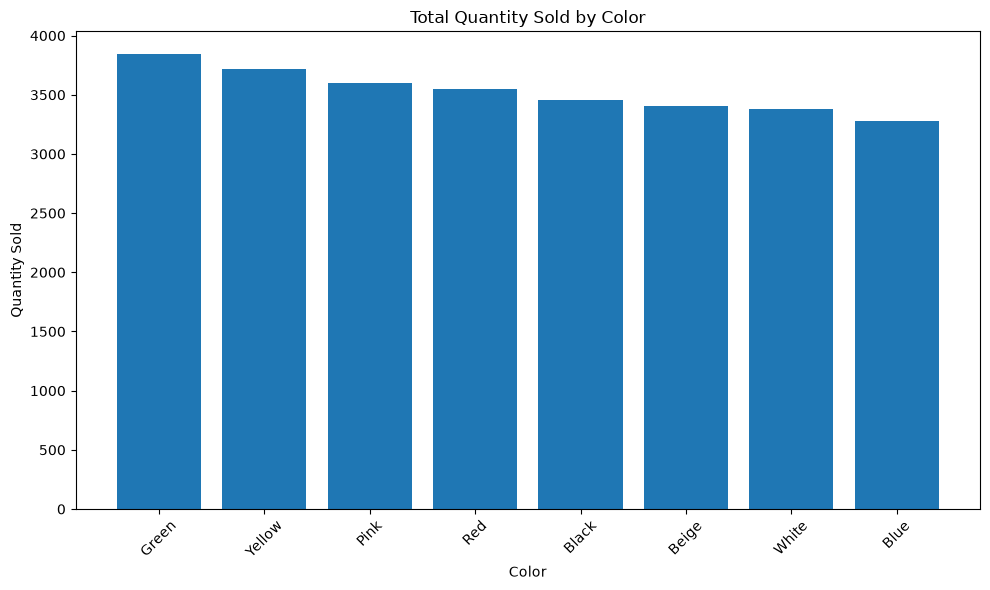

In [49]:
#color demand chart
plt.figure(figsize=(10, 6))

plt.bar(
    color_sales.index,
    color_sales["Total_Quantity"]
)

plt.title("Total Quantity Sold by Color")
plt.xlabel("Color")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "outputs/charts/color_demand.png",
    dpi=300
)

plt.show()

In [50]:
#sales by design
design_sales = (
    sales_df
    .groupby("Design")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Number_of_Orders=("Order_ID", "count")
    )
    .sort_values(
        "Total_Quantity",
        ascending=False
    )
)

design_sales

,Total_Quantity,Total_Revenue,Number_of_Orders
Design,,,
Printed,5476,3938844.00,1054
Floral,4949,3576420.10,1016
Traditional,4820,3518669.65,977
Geometric,4447,3198739.05,1001
Abstract,4336,3149063.50,989
Minimal,4211,3069537.50,963


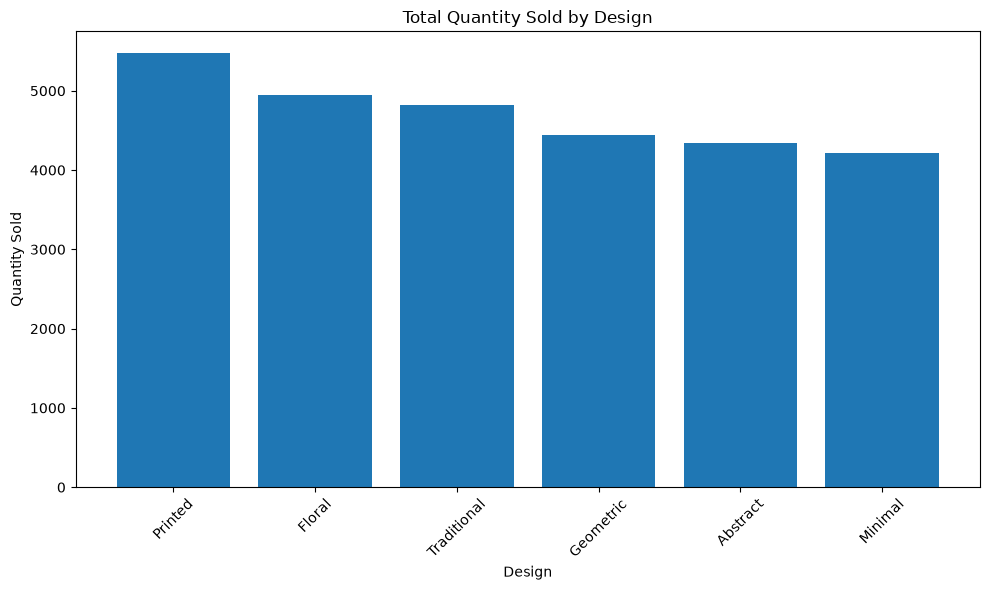

In [51]:
#design demand chart
plt.figure(figsize=(10, 6))

plt.bar(
    design_sales.index,
    design_sales["Total_Quantity"]
)

plt.title("Total Quantity Sold by Design")
plt.xlabel("Design")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "outputs/charts/design_demand.png",
    dpi=300
)

plt.show()

In [52]:
#monthly sales
monthly_sales = (
    sales_df
    .groupby("Month")
    .agg(
        Quantity=("Quantity", "sum"),
        Revenue=("Revenue", "sum")
    )
)

monthly_sales

,Quantity,Revenue
Month,,
1,2019,1447317.05
2,1960,1433358.50
3,2567,1837019.75
4,2596,1873844.05
5,2863,2049976.65
6,2259,1634657.85
7,2097,1474806.05
8,2235,1654395.30
9,1867,1388086.65


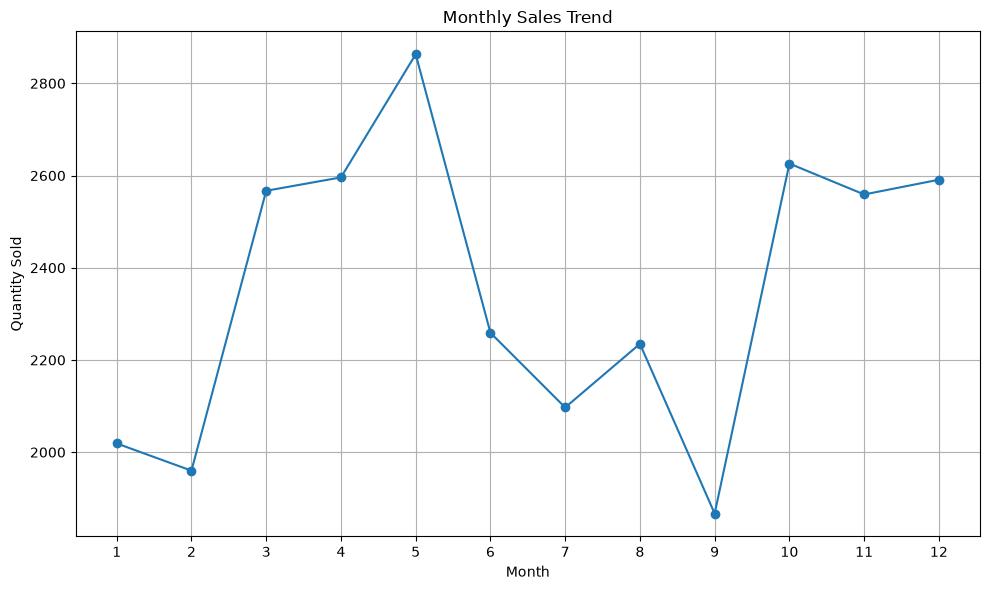

In [53]:
#monthly sales chart
plt.figure(figsize=(10, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales["Quantity"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")

plt.xticks(range(1, 13))

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "outputs/charts/monthly_sales_trend.png",
    dpi=300
)

plt.show()

In [54]:
#seasonals sales analysis
season_sales = (
    sales_df
    .groupby("Season")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Number_of_Orders=("Order_ID", "count")
    )
    .sort_values(
        "Total_Quantity",
        ascending=False
    )
)

season_sales

,Total_Quantity,Total_Revenue,Number_of_Orders
Season,,,
Summer,8026,5760840.45,1522
Festive,7052,5155980.70,1453
Monsoon,6591,4763859.20,1557
Winter,6570,4770593.45,1468


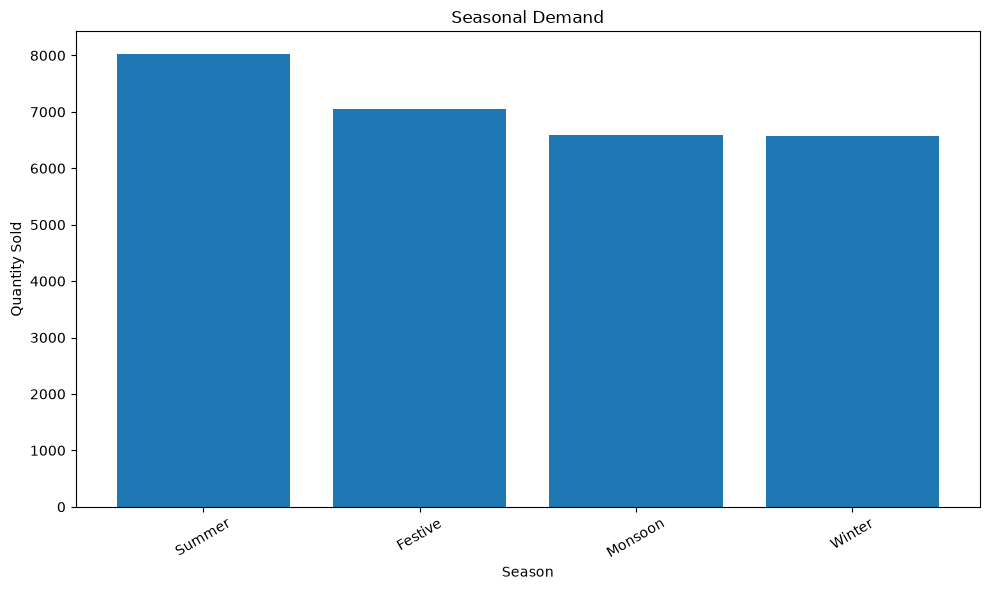

In [55]:
plt.figure(figsize=(10, 6))

plt.bar(
    season_sales.index,
    season_sales["Total_Quantity"]
)

plt.title("Seasonal Demand")
plt.xlabel("Season")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    "outputs/charts/seasonal_demand.png",
    dpi=300
)

plt.show()

In [56]:
#color+seasonal analysis
color_season = pd.pivot_table(
    sales_df,
    values="Quantity",
    index="Color",
    columns="Season",
    aggfunc="sum",
    fill_value=0
)

color_season

Season,Festive,Monsoon,Summer,Winter
Color,,,,
Beige,937,847,898,726
Black,933,782,810,929
Blue,748,915,822,791
Green,976,988,958,922
Pink,766,695,1390,750
Red,1074,815,820,844
White,799,763,1022,800
Yellow,819,786,1306,808


In [57]:
#design+seasonal sales analysis
design_season = pd.pivot_table(
    sales_df,
    values="Quantity",
    index="Design",
    columns="Season",
    aggfunc="sum",
    fill_value=0
)

design_season

Season,Festive,Monsoon,Summer,Winter
Design,,,,
Abstract,961,1056,1265,1054
Floral,1175,1065,1644,1065
Geometric,1182,1192,1156,917
Minimal,1085,981,1131,1014
Printed,1320,1155,1677,1324
Traditional,1329,1142,1153,1196


In [58]:
#best color for each season
best_color_by_season = (
    sales_df
    .groupby(["Season", "Color"])["Quantity"]
    .sum()
    .reset_index()
)

best_color_by_season = (
    best_color_by_season
    .sort_values(
        ["Season", "Quantity"],
        ascending=[True, False]
    )
)

best_color_by_season.groupby("Season").head(1)

,Season,Color,Quantity
5,Festive,Red,1074
11,Monsoon,Green,988
20,Summer,Pink,1390
25,Winter,Black,929


In [59]:
#best design for each season
best_design_by_season = (
    sales_df
    .groupby(["Season", "Design"])["Quantity"]
    .sum()
    .reset_index()
)

best_design_by_season = (
    best_design_by_season
    .sort_values(
        ["Season", "Quantity"],
        ascending=[True, False]
    )
)

best_design_by_season.groupby("Season").head(1)

,Season,Design,Quantity
5,Festive,Traditional,1329
8,Monsoon,Geometric,1192
16,Summer,Printed,1677
22,Winter,Printed,1324


In [60]:
#scoring
# Historical demand
historical_demand = (
    sales_df
    .groupby(["Color", "Design"])["Quantity"]
    .sum()
    .reset_index(name="Historical_Demand")
)

# Seasonal demand
seasonal_demand = (
    sales_df[sales_df["Is_Peak_Period"]]
    .groupby(["Color", "Design"])["Quantity"]
    .sum()
    .reset_index(name="Seasonal_Demand")
)

# Recent demand - latest 6 months in the dataset
latest_date = sales_df["Order_Date"].max()

recent_sales = sales_df[
    sales_df["Order_Date"] >=
    latest_date - pd.DateOffset(months=6)
]

recent_demand = (
    recent_sales
    .groupby(["Color", "Design"])["Quantity"]
    .sum()
    .reset_index(name="Recent_Demand")
)

# Combine
demand_score = historical_demand.merge(
    seasonal_demand,
    on=["Color", "Design"],
    how="left"
)

demand_score = demand_score.merge(
    recent_demand,
    on=["Color", "Design"],
    how="left"
)

demand_score = demand_score.fillna(0)

# Normalize metrics
for column in [
    "Historical_Demand",
    "Seasonal_Demand",
    "Recent_Demand"
]:

    max_value = demand_score[column].max()

    demand_score[column + "_Score"] = (
        demand_score[column] / max_value * 100
    )

# Growth rate
demand_score["Growth_Rate"] = (
    demand_score["Recent_Demand"] /
    (demand_score["Historical_Demand"] / 6 + 1)
)

max_growth = demand_score["Growth_Rate"].max()

demand_score["Growth_Score"] = (
    demand_score["Growth_Rate"] /
    max_growth * 100
)

# Final demand score
demand_score["Demand_Score"] = (
    0.40 * demand_score["Historical_Demand_Score"]
    + 0.25 * demand_score["Seasonal_Demand_Score"]
    + 0.20 * demand_score["Recent_Demand_Score"]
    + 0.15 * demand_score["Growth_Score"]
)

demand_score = demand_score.sort_values(
    "Demand_Score",
    ascending=False
)

demand_score.head(15)

,Color,Design,Historical_Demand,Seasonal_Demand,Recent_Demand,Historical_Demand_Score,Seasonal_Demand_Score,Recent_Demand_Score,Growth_Rate,Growth_Score,Demand_Score
46,Yellow,Printed,758,596,117,100.000000,100.000000,76.973684,0.918848,64.019998,89.997736
23,Green,Traditional,657,373,152,86.675462,62.583893,100.000000,1.375566,95.841413,84.692370
17,Blue,Traditional,649,371,152,85.620053,62.248322,100.000000,1.392366,97.011996,84.361901
34,Red,Printed,718,476,120,94.722955,79.865772,78.947368,0.994475,69.289245,84.038485
20,Green,Geometric,638,357,149,84.168865,59.899329,98.026316,1.388199,96.721618,82.755884
28,Pink,Printed,720,517,101,94.986807,86.744966,66.447368,0.834711,58.157791,81.694107
13,Blue,Floral,609,366,141,80.343008,61.409396,92.763158,1.375610,95.844489,80.418857
31,Red,Floral,645,418,122,85.092348,70.134228,80.263158,1.124424,78.343324,79.374627
22,Green,Printed,723,448,99,95.382586,75.167785,65.131579,0.814815,56.771559,78.487030
41,White,Traditional,661,373,112,87.203166,62.583893,73.684211,1.007496,70.196481,75.793554


In [61]:
#demand category
def demand_category(score):

    if score >= 75:
        return "Very High"

    elif score >= 50:
        return "High"

    elif score >= 25:
        return "Medium"

    else:
        return "Low"


demand_score["Demand_Category"] = (
    demand_score["Demand_Score"]
    .apply(demand_category)
)

demand_score[
    [
        "Color",
        "Design",
        "Demand_Score",
        "Demand_Category"
    ]
].head(20)

,Color,Design,Demand_Score,Demand_Category
46,Yellow,Printed,89.997736,Very High
23,Green,Traditional,84.692370,Very High
17,Blue,Traditional,84.361901,Very High
34,Red,Printed,84.038485,Very High
20,Green,Geometric,82.755884,Very High
28,Pink,Printed,81.694107,Very High
13,Blue,Floral,80.418857,Very High
31,Red,Floral,79.374627,Very High
22,Green,Printed,78.487030,Very High
41,White,Traditional,75.793554,Very High


In [62]:
#top predicted product
top_products = demand_score[
    [
        "Color",
        "Design",
        "Historical_Demand",
        "Seasonal_Demand",
        "Recent_Demand",
        "Demand_Score",
        "Demand_Category"
    ]
].head(10)

top_products

,Color,Design,Historical_Demand,Seasonal_Demand,Recent_Demand,Demand_Score,Demand_Category
46,Yellow,Printed,758,596,117,89.997736,Very High
23,Green,Traditional,657,373,152,84.692370,Very High
17,Blue,Traditional,649,371,152,84.361901,Very High
34,Red,Printed,718,476,120,84.038485,Very High
20,Green,Geometric,638,357,149,82.755884,Very High
28,Pink,Printed,720,517,101,81.694107,Very High
13,Blue,Floral,609,366,141,80.418857,Very High
31,Red,Floral,645,418,122,79.374627,Very High
22,Green,Printed,723,448,99,78.487030,Very High
41,White,Traditional,661,373,112,75.793554,Very High


**Findings**
============

### Assignment:

Create a data model to collect, organize, and analyze sales data from Shopify. Using historical sales data, develop an analytical/prediction approach to identify which colors and designs are likely to be in higher demand during peak or seasonal periods.

The analysis demonstrates how historical sales trends and seasonal patterns can be used to generate meaningful insights and support product planning and inventory decisions.

### Model:

**Data:**
The dataset is synthetically created based on the requirements of the assignment because the actual Shopify sales dataset was not provided.

The model contains the following steps:

1. **Importing necessary libraries**

   * Pandas
   * NumPy
   * Matplotlib
   * Scikit-learn

2. **Creating synthetic Shopify sales data**

   * Order details
   * Product details
   * Category
   * Color
   * Design
   * Quantity
   * Price
   * Discount
   * Revenue

3. **Data quality checking**

   * Checked missing values
   * Checked duplicate records
   * Checked data types
   * Reviewed basic statistics

4. **Time and seasonal feature creation**

   * Year
   * Month
   * Quarter
   * Season
   * Peak-period indicator

5. **Historical sales analysis**

   * Analyzed total sales and revenue
   * Identified high-demand colors
   * Identified high-demand designs
   * Analyzed monthly sales trends

6. **Seasonal analysis**

   * Compared demand across seasons
   * Analyzed color demand by season
   * Analyzed design demand by season

7. **Color and design combination analysis**

   * Identified high-performing color-design combinations
   * Compared their historical sales performance

8. **Demand scoring**
   A demand score was created using:

   * Historical demand – 40%
   * Seasonal demand – 25%
   * Recent demand – 20%
   * Growth rate – 15%

9. **Demand categorization**
   Products were categorized into:

   * Very High Demand
   * High Demand
   * Medium Demand
   * Low Demand

10. **Business insights**
    The analysis can help identify products that may require higher inventory before peak or seasonal periods.

### Key Findings:

* Historical sales data helps identify consistently high-performing colors and designs.
* Seasonal analysis helps identify colors and designs that perform better during specific periods.
* Color-design combinations provide more useful product-level insights than analyzing color or design individually.
* Recent demand and growth trends can help identify products whose demand is increasing.
* A combined demand score provides a simple way to prioritize products for inventory planning.
* Products with higher demand scores can be considered for higher stock allocation during expected peak periods.
* Products with lower demand scores can be reviewed to reduce the risk of excess inventory.

### Business Recommendation:

The demand scoring approach can be used as a decision-support tool for inventory and product planning. Before seasonal periods, products with strong historical, seasonal, and recent demand should be prioritized for stocking.

**Note:** Since the dataset is synthetic, the findings demonstrate the analytical approach rather than representing actual Shopify customer sales behavior. The same methodology can be applied to the actual Shopify dataset when it is available.
